# 07 - Error Analysis (Module 1)

**Author:** Faizan NORAT

**Week 3 - Model Development and Experimentation**

The objective of this notebook is to understand the
errors made by our multi-label emotion classification
models on GoEmotions.

We compare the Week 2 baseline with the ensemble
models developed in Week 3.

Main objectives:
- Identify frequent false positives and false negatives.
- Investigate confusion between related emotions.
- Examine misclassified comments.
- Compare errors across models.
- Review the stacking methodology for potential leakage.

All analyses are conducted on the validation set.
The test set is reserved for final evaluation.

In [61]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    multilabel_confusion_matrix,
    f1_score
)

sys.path.append(os.path.join("..", "src"))

from evaluation import (
    LABELS_28,
    to_multi_hot,
    tune_thresholds,
    apply_thresholds,
    per_class_report,
    compute_metrics
)

SEED = 42
np.random.seed(SEED)

DATA_DIR = os.path.join("..", "data", "processed")
BASELINE_DIR = os.path.join("..", "results", "baselines")
ENSEMBLE_DIR = os.path.join("..", "results", "ensembles")
OUT_DIR = os.path.join("..", "results", "error_analysis")

os.makedirs(OUT_DIR, exist_ok=True)

## 1. Data and predictions

We use the prepared validation split generated by
`01_eda_simple.ipynb`.

Saved probabilities from the baseline and ensemble
models are loaded in the shared LABELS_28 order.

The test set is not loaded in this notebook.

In [62]:
df_val = pd.read_parquet(
    os.path.join(DATA_DIR, "validation.parquet")
)

y_val = to_multi_hot(
    df_val["labels_28"], LABELS_28
)

print("Validation comments:", len(df_val))
print("Target shape:", y_val.shape)
print("Available columns:", df_val.columns.tolist())

assert len(df_val) == 5377
assert y_val.shape == (5377, 28)

Validation comments: 5377
Target shape: (5377, 28)
Available columns: ['id', 'text', 'text_raw', 'labels_28', 'labels_ekman', 'labels_sentiment']


In [63]:
probabilities = {
    "baseline": np.load(
        os.path.join(BASELINE_DIR, "proba_val_best.npy")
    ),
    "soft_voting": np.load(
        os.path.join(ENSEMBLE_DIR, "proba_val_voting_soft.npy")
    ),
    "stacking": np.load(
        os.path.join(ENSEMBLE_DIR, "proba_val_stacking.npy")
    ),
    "random_forest": np.load(
        os.path.join(ENSEMBLE_DIR, "proba_val_forest.npy")
    ),
    "bagging": np.load(
        os.path.join(ENSEMBLE_DIR, "proba_val_bagging_logreg.npy")
    )
}

for name, proba in probabilities.items():
    assert proba.shape == y_val.shape
    assert np.isfinite(proba).all()
    assert ((proba >= 0) & (proba <= 1)).all()

    print(name, proba.shape, "- OK")

baseline (5377, 28) - OK
soft_voting (5377, 28) - OK
stacking (5377, 28) - OK
random_forest (5377, 28) - OK
bagging (5377, 28) - OK


## 2. Reproduction of validation scores

To remain consistent with notebooks 03 and 05, we
reproduce the same two-fold threshold cross-fitting
procedure.

Thresholds are tuned on one half of validation and
applied to the other half. The process is then reversed.

This reduces optimism caused by tuning and evaluating
thresholds on the same comments.

In [64]:
def crossfit_predict(y_true, proba, seed=SEED):
    rng = np.random.RandomState(seed)
    order = rng.permutation(len(y_true))

    half_a = order[:len(order) // 2]
    half_b = order[len(order) // 2:]

    y_pred = np.zeros_like(y_true)

    for tune_idx, apply_idx in [
        (half_a, half_b),
        (half_b, half_a)
    ]:
        thresholds = tune_thresholds(
            y_true[tune_idx],
            proba[tune_idx]
        )

        y_pred[apply_idx] = apply_thresholds(
            proba[apply_idx],
            thresholds
        )

    return y_pred

In [65]:
predictions = {
    name: crossfit_predict(y_val, proba)
    for name, proba in probabilities.items()
}

results = pd.DataFrame([
    {
        "model": name,
        **compute_metrics(y_val, pred)
    }
    for name, pred in predictions.items()
])

results.round(4)

,model,macro_f1,micro_f1,weighted_f1,exact_match
0,baseline,0.4771,0.5211,0.5348,0.3085
1,soft_voting,0.4952,0.5498,0.5547,0.3452
2,stacking,0.4835,0.5436,0.5537,0.3204
3,random_forest,0.4470,0.5192,0.5229,0.3320
4,bagging,0.4761,0.5257,0.5353,0.2996


## 3. Per-label error analysis

Since GoEmotions is a multi-label classification task,
a standard multiclass confusion matrix is not appropriate.

We compute a binary confusion matrix for each emotion
to identify false positives and false negatives.

The baseline is used as our first reference.

In [66]:
y_pred_base = predictions["baseline"]

matrices = multilabel_confusion_matrix(
    y_val,
    y_pred_base
)

error_table = pd.DataFrame({
    "emotion": LABELS_28,
    "TN": matrices[:, 0, 0],
    "FP": matrices[:, 0, 1],
    "FN": matrices[:, 1, 0],
    "TP": matrices[:, 1, 1]
})

error_table["support"] = (
    error_table["TP"] + error_table["FN"]
)

error_table["total_errors"] = (
    error_table["FP"] + error_table["FN"]
)

error_table.sort_values(
    "total_errors", ascending=False
)

,emotion,TN,FP,FN,TP,support,total_errors
27,neutral,2306,1312,350,1409,1759,1662
4,approval,4409,574,230,164,394,804
3,annoyance,4573,501,172,131,303,673
10,disapproval,4678,407,164,128,292,571
9,disappointment,4952,263,114,48,162,377
0,admiration,4702,190,157,328,485,347
7,curiosity,4901,229,99,148,247,328
6,confusion,5003,225,77,72,149,302
2,anger,5003,182,94,98,192,276
5,caring,5069,156,91,61,152,247


In [67]:
error_table["false_negative_rate"] = (
    error_table["FN"] /
    error_table["support"]
)

error_table["false_discovery_rate"] = (
    error_table["FP"] /
    (error_table["TP"] + error_table["FP"]).replace(0, np.nan)
)

error_table.round(3).sort_values(
    "false_negative_rate",
    ascending=False
)

,emotion,TN,FP,FN,TP,support,total_errors,false_negative_rate,false_discovery_rate
13,excitement,5243,40,79,15,94,119,0.840,0.727
23,relief,5352,7,15,3,18,22,0.833,0.700
22,realization,5180,70,102,25,127,172,0.803,0.737
9,disappointment,4952,263,114,48,162,377,0.704,0.846
19,nervousness,5347,9,14,7,21,23,0.667,0.562
11,disgust,5228,53,58,38,96,111,0.604,0.582
5,caring,5069,156,91,61,152,247,0.599,0.719
4,approval,4409,574,230,164,394,804,0.584,0.778
3,annoyance,4573,501,172,131,303,673,0.568,0.793
10,disapproval,4678,407,164,128,292,571,0.562,0.761


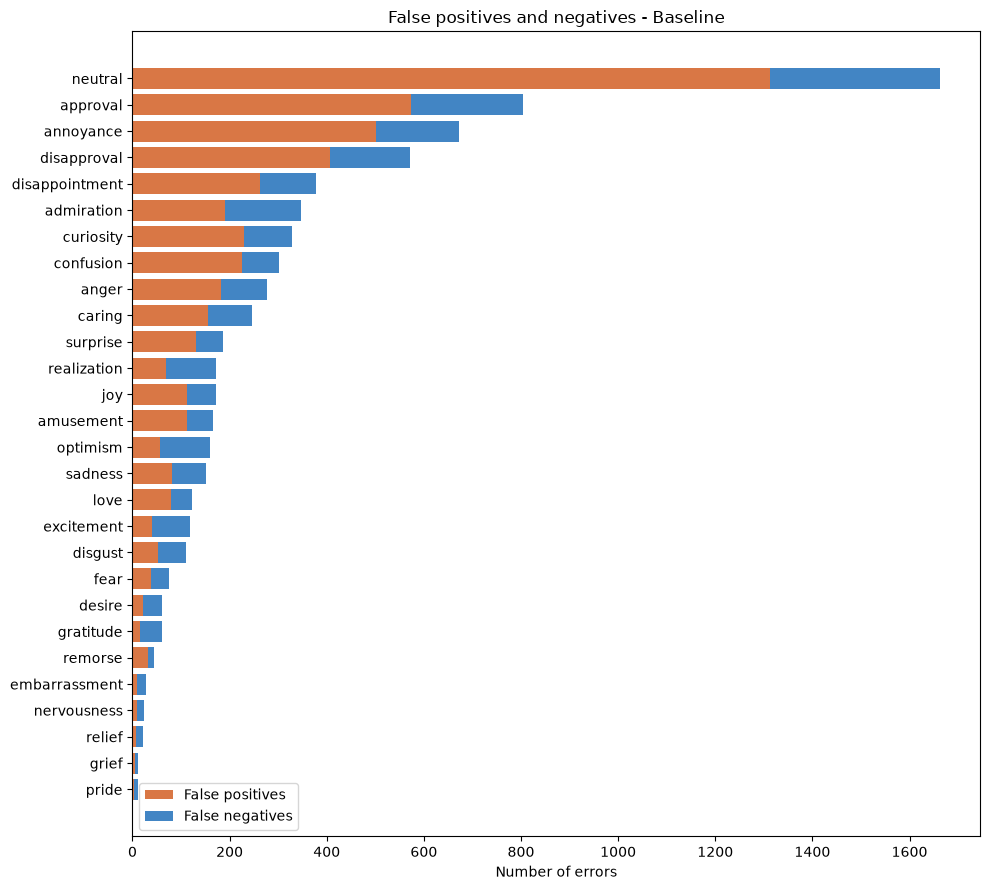

In [68]:
plot_df = error_table.sort_values(
    "total_errors", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 9))

ax.barh(
    plot_df["emotion"],
    plot_df["FP"],
    label="False positives",
    color="#D97745"
)

ax.barh(
    plot_df["emotion"],
    plot_df["FN"],
    left=plot_df["FP"],
    label="False negatives",
    color="#4285C4"
)

ax.set_xlabel("Number of errors")
ax.set_title("False positives and negatives - Baseline")
ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "per_label_errors.png"),
    dpi=150
)

plt.show()

error_table.to_csv(
    os.path.join(OUT_DIR, "per_label_errors.csv"),
    index=False
)

## 4. Emotion confusion analysis

In a multi-label problem, several true and predicted
labels can be associated with the same comment.

We therefore examine the co-occurrence of missed true
labels (false negatives) and incorrectly predicted
labels (false positives).

These associations indicate potential confusion
patterns, rather than direct one-to-one substitutions.

In [69]:
def error_confusion_matrix(y_true, y_pred):
    false_negatives = (
        (y_true == 1) & (y_pred == 0)
    ).astype(int)

    false_positives = (
        (y_true == 0) & (y_pred == 1)
    ).astype(int)

    return false_negatives.T @ false_positives


confusion = error_confusion_matrix(
    y_val,
    y_pred_base
)

confusion_df = pd.DataFrame(
    confusion,
    index=LABELS_28,
    columns=LABELS_28
)

confusion_df

,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,disappointment,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
admiration,0,5,4,10,20,8,4,9,1,7,...,7,0,1,0,0,0,0,4,9,68
amusement,7,0,2,5,7,2,3,3,0,5,...,1,0,0,0,2,0,0,2,2,25
anger,2,1,0,20,8,4,5,7,0,5,...,0,0,0,0,1,0,0,2,0,60
annoyance,4,4,14,0,14,4,11,9,2,9,...,2,0,0,0,2,0,0,1,6,100
approval,15,9,8,23,0,15,4,9,1,10,...,5,0,0,0,6,0,0,3,5,121
caring,4,2,0,8,10,0,2,2,0,4,...,1,0,3,0,1,0,0,4,0,59
confusion,1,2,3,10,7,0,0,20,0,3,...,0,0,0,0,2,0,0,1,2,43
curiosity,3,0,3,9,9,3,7,0,0,1,...,1,1,1,0,0,0,3,3,2,53
desire,2,1,1,1,4,1,1,2,0,2,...,3,0,6,0,3,0,1,0,2,16
disappointment,6,2,2,17,11,1,2,2,0,0,...,2,2,1,0,5,0,0,3,1,60


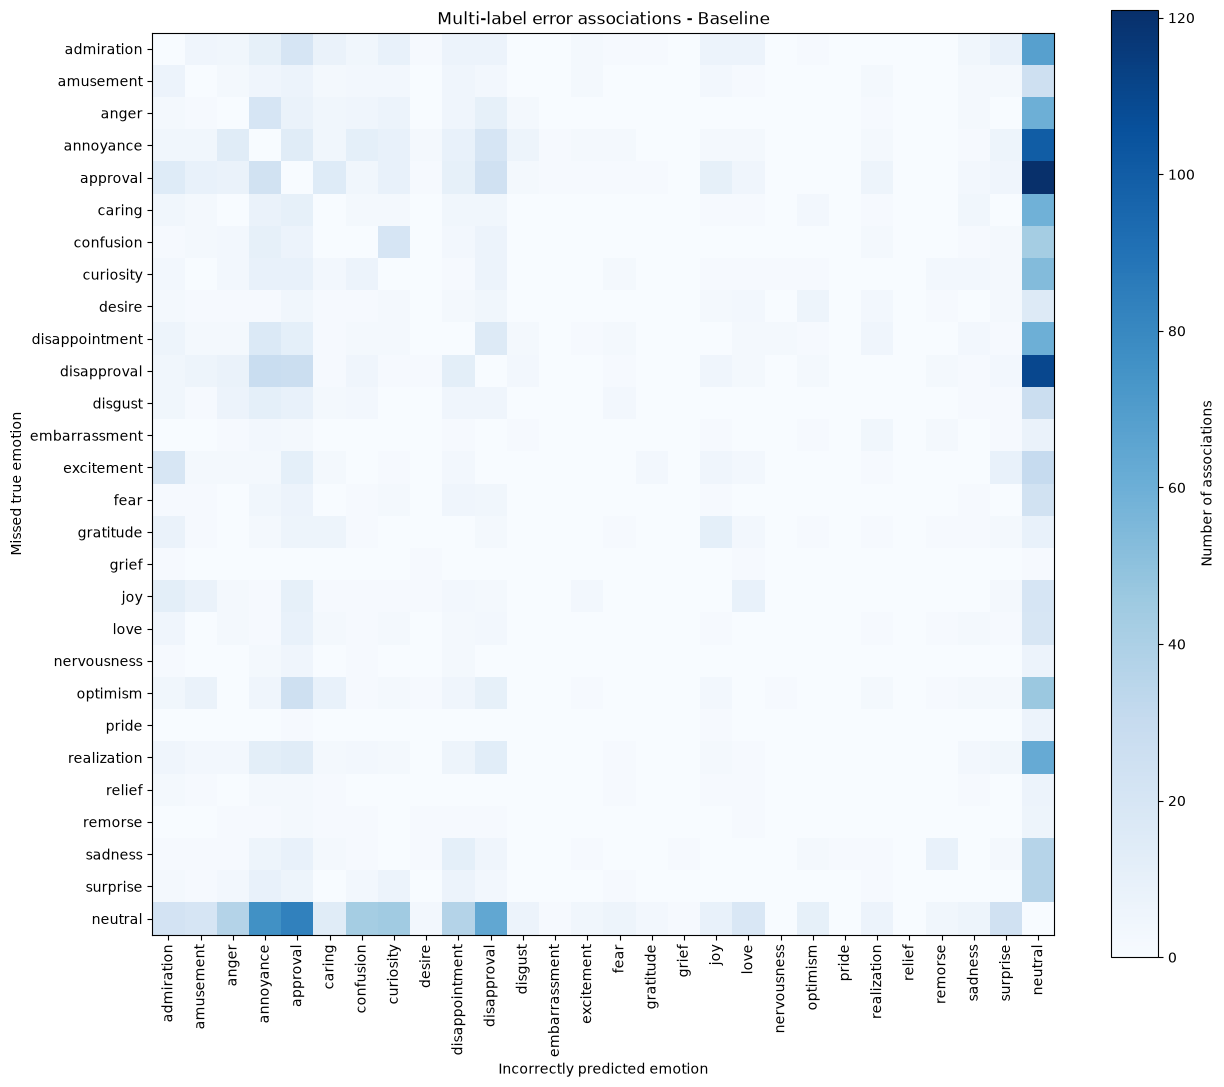

In [70]:
fig, ax = plt.subplots(figsize=(13, 11))

im = ax.imshow(confusion, cmap="Blues")

ax.set_xticks(range(len(LABELS_28)))
ax.set_yticks(range(len(LABELS_28)))

ax.set_xticklabels(LABELS_28, rotation=90)
ax.set_yticklabels(LABELS_28)

ax.set_xlabel("Incorrectly predicted emotion")
ax.set_ylabel("Missed true emotion")

ax.set_title(
    "Multi-label error associations - Baseline"
)

fig.colorbar(im, ax=ax, label="Number of associations")

plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "error_confusion_heatmap.png"),
    dpi=150
)

plt.show()

In [71]:
confusion_pairs = (
    confusion_df
    .rename_axis("missed_emotion")
    .reset_index()
    .melt(
        id_vars="missed_emotion",
        var_name="incorrect_prediction",
        value_name="count"
    )
)

confusion_pairs = confusion_pairs[
    confusion_pairs["count"] > 0
].sort_values("count", ascending=False)

confusion_pairs.head(15)

,missed_emotion,incorrect_prediction,count
760,approval,neutral,121
766,disapproval,neutral,110
759,annoyance,neutral,100
139,neutral,approval,83
111,neutral,annoyance,76
756,admiration,neutral,68
307,neutral,disapproval,64
778,realization,neutral,62
758,anger,neutral,60
765,disappointment,neutral,60


### Interpretation of the baseline errors

Neutral generates the largest number of errors, with
1,312 false positives and 350 false negatives. This
indicates that the baseline tends to overpredict Neutral.

Approval, Annoyance and Disapproval also generate many
errors, suggesting difficulties in distinguishing
related or ambiguous emotional expressions.

In relative terms, Excitement (84.0%), Relief (83.3%)
and Realization (80.3%) have the highest false negative
rates. However, results for rare labels such as Relief
must be interpreted carefully because of their small
validation support.

Gratitude is much easier to detect, with a false
negative rate of 13.1% and a false discovery rate
of only 5.1%.

These results suggest that class imbalance and the
availability of explicit lexical cues may both
influence model performance.

### Interpretation of emotion confusion

All 15 most frequent error associations involve
Neutral.

The most frequent patterns are missed Approval (121),
Disapproval (110) and Annoyance (100), combined with
an incorrect prediction of Neutral.

The opposite pattern also occurs: Neutral is sometimes
missed while Approval or Annoyance is incorrectly
predicted.

These results highlight the difficulty of distinguishing
emotionally neutral comments from subtle emotional
expressions.

However, raw error counts are influenced by label
frequency. These associations do not necessarily
represent direct substitutions between emotions.

In [72]:
non_neutral_pairs = confusion_pairs[
    (confusion_pairs["missed_emotion"] != "neutral") &
    (confusion_pairs["incorrect_prediction"] != "neutral")
]

non_neutral_pairs.head(15)

,missed_emotion,incorrect_prediction,count
94,disapproval,annoyance,28
122,disapproval,approval,27
132,optimism,approval,25
284,approval,disapproval,24
88,approval,annoyance,23
283,annoyance,disapproval,20
86,anger,annoyance,20
112,admiration,approval,20
202,confusion,curiosity,20
13,excitement,admiration,19


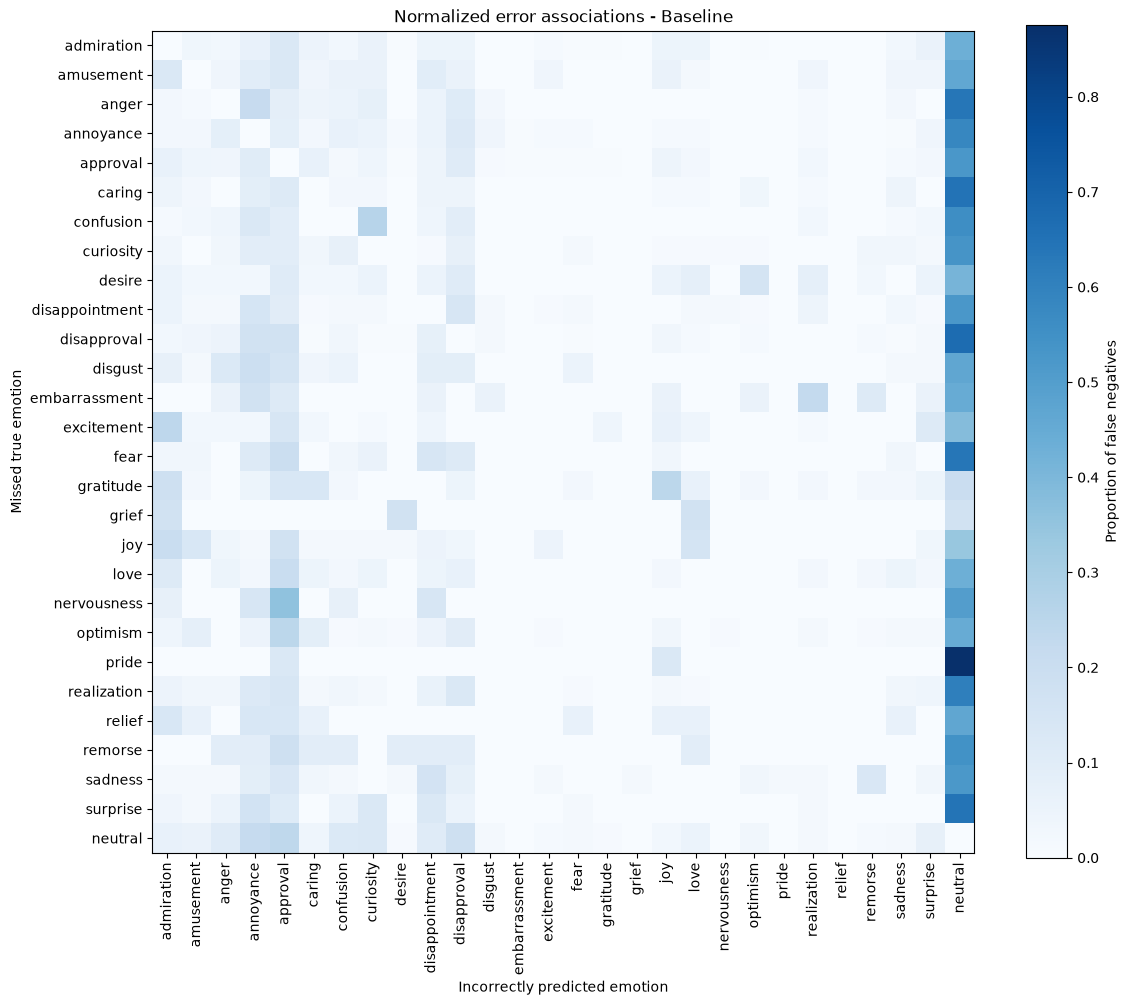

In [73]:
normalized_confusion = confusion_df.div(
    error_table.set_index("emotion")["FN"].replace(0, np.nan),
    axis=0
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(normalized_confusion, cmap="Blues")

ax.set_xticks(range(len(LABELS_28)))
ax.set_yticks(range(len(LABELS_28)))

ax.set_xticklabels(LABELS_28, rotation=90)
ax.set_yticklabels(LABELS_28)

ax.set_xlabel("Incorrectly predicted emotion")
ax.set_ylabel("Missed true emotion")
ax.set_title("Normalized error associations - Baseline")

fig.colorbar(im, ax=ax, label="Proportion of false negatives")

plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "normalized_confusion.png"),
    dpi=150
)

plt.show()

### Error associations excluding Neutral

After excluding Neutral, the most frequent error
associations involve Disapproval, Annoyance and Approval.

We also observe associations between Anger and
Annoyance, and between Confusion and Curiosity.

These patterns are consistent with the difficulty of
distinguishing semantically related emotions.

However, some associations involve apparently opposite
emotions, such as Approval and Disapproval, suggesting
that context and linguistic ambiguity may also play a role.

The normalized heatmap helps account for differences
in label frequency.

## 5. Qualitative error analysis

Quantitative metrics identify difficult emotions but
do not explain why individual predictions fail.

We extract misclassified validation comments and
manually investigate possible causes, such as sarcasm,
negation, ambiguity, missing context and annotation
uncertainty.

In [74]:
def decode_labels(vector):
    return [
        label for label, value in zip(LABELS_28, vector)
        if value == 1
    ]


text_column = (
    "text_raw" if "text_raw" in df_val.columns else "text"
)

examples = df_val[["id", text_column]].copy()
examples = examples.rename(columns={text_column: "text"})

examples["true_labels"] = [
    decode_labels(row) for row in y_val
]

examples["predicted_labels"] = [
    decode_labels(row) for row in y_pred_base
]

examples["missed_labels"] = [
    decode_labels((true == 1) & (pred == 0))
    for true, pred in zip(y_val, y_pred_base)
]

examples["incorrect_labels"] = [
    decode_labels((true == 0) & (pred == 1))
    for true, pred in zip(y_val, y_pred_base)
]

examples["n_errors"] = (
    y_val != y_pred_base
).sum(axis=1)

errors = examples[examples["n_errors"] > 0].copy()

print("Misclassified comments:", len(errors))
print("Total validation comments:", len(df_val))
print("Error rate:", round(len(errors) / len(df_val), 4))

Misclassified comments: 3718
Total validation comments: 5377
Error rate: 0.6915


In [75]:
sample_errors = errors.sample(
    n=min(50, len(errors)),
    random_state=SEED
).copy()

sample_errors["error_category"] = ""
sample_errors["interpretation"] = ""

csv_path = os.path.join(OUT_DIR, "error_examples.csv")

if not os.path.exists(csv_path):
    sample_errors.to_csv(
        csv_path,
        index=False,
        encoding="utf-8-sig"
    )
    print("Annotation file created.")
else:
    print("Existing annotation file preserved.")

pd.read_csv(csv_path).head(10)

Existing annotation file preserved.


,id,text,true_labels,predicted_labels,missed_labels,incorrect_labels,n_errors,error_category,interpretation
0,ee2nuch,[NAME] wasnt elite for anywhere near 15 years....,['surprise'],['neutral'],['surprise'],['neutral'],2,Implicit emotion,The disagreement is framed as a factual correc...
1,ef7trdy,Only ever attracted to other non binaries? Hom...,"['curiosity', 'realization']",['neutral'],"['curiosity', 'realization']",['neutral'],3,Multi-label difficulty,The question and subsequent explanation expres...
2,edqmqf8,Anzac day rules are even dumber,"['annoyance', 'neutral']",['neutral'],['annoyance'],[],1,Multi-label difficulty,"The negative evaluation suggests annoyance, wh..."
3,ed6hfzq,"Oh yeah I know, but like.. _why?_ it just seem...",['confusion'],['curiosity'],['confusion'],['curiosity'],2,Ambiguity,"The question can signal curiosity, but the sur..."
4,eczsys7,Yep. Happy New Years!,['joy'],"['excitement', 'joy']",[],['excitement'],1,Ambiguity,A celebratory greeting can plausibly express b...
5,ed5lfk5,Ooh I like them. I don't really plan on marryi...,"['love', 'optimism']","['approval', 'disapproval']","['love', 'optimism']","['approval', 'disapproval']",4,Negation,The negative clause may compete with the posit...
6,edtbmhw,The StackExchange network might have turned in...,"['admiration', 'approval']",['approval'],['admiration'],[],1,Multi-label difficulty,The model detects approval but misses the stro...
7,ed9xeck,Thank you so much for all this! Nobody else se...,['gratitude'],"['annoyance', 'gratitude']",[],['annoyance'],1,Annotation uncertainty,"Gratitude is explicit, but the complaint about..."
8,ef7k88s,"He had one poor split, and he already looks st...",['neutral'],"['anger', 'annoyance']",['neutral'],"['anger', 'annoyance']",3,Annotation uncertainty,Hostile wording makes anger or annoyance plaus...
9,edoy1r1,Smoooootthhhhhhh!!,['approval'],['neutral'],['approval'],['neutral'],2,Ambiguity,The elongated expression may signal approval o...


In [76]:
reviewed_errors = pd.read_csv(csv_path)

categories = (
    reviewed_errors["error_category"]
    .fillna("")
    .str.strip()
)

category_counts = categories[
    categories != ""
].value_counts()

print("Reviewed comments:", category_counts.sum())
print("Total sample:", len(reviewed_errors))

display(category_counts)

Reviewed comments: 50
Total sample: 50


error_category
Ambiguity                 13
Multi-label difficulty    10
Implicit emotion           8
Annotation uncertainty     7
Missing context            7
Negation                   4
Other / unclear            1
Name: count, dtype: int64

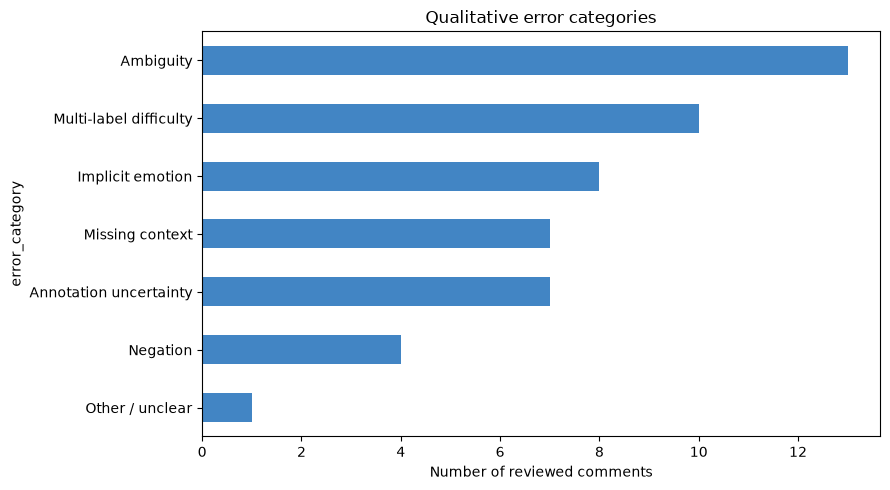

In [77]:
if category_counts.empty:
    print("No annotations available. Complete error_examples.csv first.")

else:
    category_counts.sort_values().plot(
        kind="barh",
        figsize=(9, 5),
        color="#4285C4"
    )

    plt.xlabel("Number of reviewed comments")
    plt.title("Qualitative error categories")
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUT_DIR, "error_categories.png"),
        dpi=150
    )

    plt.show()

### Interpretation of qualitative errors

The qualitative analysis covers a reproducible random
sample of 50 misclassified validation comments.

The initial AI-assisted categorization identifies
ambiguity (26%), multi-label difficulty (20%) and
implicit emotions (16%) as the most frequent
potential sources of error.

Annotation uncertainty and missing context each
represent 14% of the sample, highlighting limitations
related to subjective labels and isolated Reddit
comments.

Negation accounts for 8% of the reviewed examples.

These observations suggest that the limitations of
the baseline are not only related to class imbalance,
but also to contextual and semantic understanding.

The categorization is subjective and does not establish
the actual internal causes of model errors. The results
describe this sample rather than the entire dataset.

## 6. Comparison between models

We compare the baseline and ensemble models on the
same validation comments.

The objective is to determine whether ensembles
correct baseline errors, introduce new errors or
remain limited by the same difficult examples.

In [78]:
baseline_correct = np.all(
    y_val == predictions["baseline"],
    axis=1
)

comparison = []

for name, pred in predictions.items():

    model_correct = np.all(y_val == pred, axis=1)

    comparison.append({
        "model": name,
        "correct_comments": model_correct.sum(),
        "incorrect_comments": (~model_correct).sum(),
        "baseline_errors_corrected": (
            ~baseline_correct & model_correct
        ).sum(),
        "new_errors": (
            baseline_correct & ~model_correct
        ).sum(),
        "shared_errors": (
            ~baseline_correct & ~model_correct
        ).sum()
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,model,correct_comments,incorrect_comments,baseline_errors_corrected,new_errors,shared_errors
0,baseline,1659,3718,0,0,3718
1,soft_voting,1856,3521,450,253,3268
2,stacking,1723,3654,479,415,3239
3,random_forest,1785,3592,603,477,3115
4,bagging,1611,3766,209,257,3509


In [79]:
base_label_errors = y_val != predictions["baseline"]

label_comparison = []

for name, pred in predictions.items():

    model_errors = y_val != pred

    label_comparison.append({
        "model": name,
        "total_label_errors": model_errors.sum(),
        "corrected_label_errors": (
            base_label_errors & ~model_errors
        ).sum(),
        "new_label_errors": (
            ~base_label_errors & model_errors
        ).sum()
    })

label_comparison_df = pd.DataFrame(label_comparison)

label_comparison_df

,model,total_label_errors,corrected_label_errors,new_label_errors
0,baseline,7281,0,0
1,soft_voting,6646,1715,1080
2,stacking,6909,2144,1772
3,random_forest,6950,2723,2392
4,bagging,7312,933,964


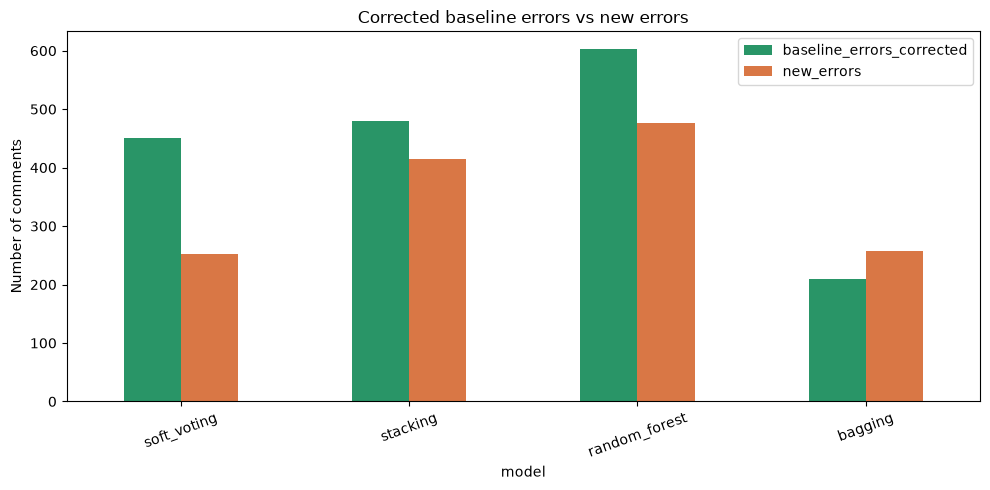

In [80]:
plot_df = comparison_df[
    comparison_df["model"] != "baseline"
]

plot_df.set_index("model")[
    ["baseline_errors_corrected", "new_errors"]
].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#299567", "#D97745"]
)

plt.ylabel("Number of comments")
plt.title("Corrected baseline errors vs new errors")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "model_error_comparison.png"),
    dpi=150
)

plt.show()

comparison_df.to_csv(
    os.path.join(OUT_DIR, "model_error_comparison.csv"),
    index=False
)

label_comparison_df.to_csv(
    os.path.join(OUT_DIR, "label_error_comparison.csv"),
    index=False
)

### Interpretation of model error comparison

Soft Voting provides the best overall improvement
in terms of exact-match errors.

It corrects 450 comments misclassified by the baseline
while introducing 253 new errors, resulting in a net
reduction of 197 misclassified comments.

At the label level, the total number of errors decreases
from 7,281 to 6,646.

Stacking and Random Forest also correct baseline errors,
but introduce more new errors than Soft Voting.

Random Forest improves exact match despite having a lower
macro-F1 than the baseline. This illustrates that different
evaluation metrics capture different aspects of performance.

Bagging does not improve the total number of errors.

In [81]:
f1_baseline = f1_score(
    y_val,
    predictions["baseline"],
    average=None,
    zero_division=0
)

f1_voting = f1_score(
    y_val,
    predictions["soft_voting"],
    average=None,
    zero_division=0
)

gain_df = pd.DataFrame({
    "emotion": LABELS_28,
    "baseline_f1": f1_baseline,
    "soft_voting_f1": f1_voting
})

gain_df["f1_gain"] = (
    gain_df["soft_voting_f1"] -
    gain_df["baseline_f1"]
)

gain_df.sort_values("f1_gain", ascending=False).round(4)

,emotion,baseline_f1,soft_voting_f1,f1_gain
13,excitement,0.2013,0.2778,0.0764
21,pride,0.5600,0.6154,0.0554
25,sadness,0.4916,0.5430,0.0515
22,realization,0.2252,0.2764,0.0512
9,disappointment,0.2030,0.2538,0.0508
26,surprise,0.4398,0.4852,0.0455
7,curiosity,0.4744,0.5090,0.0346
6,confusion,0.3229,0.3571,0.0343
3,annoyance,0.2802,0.3099,0.0297
0,admiration,0.6540,0.6798,0.0257


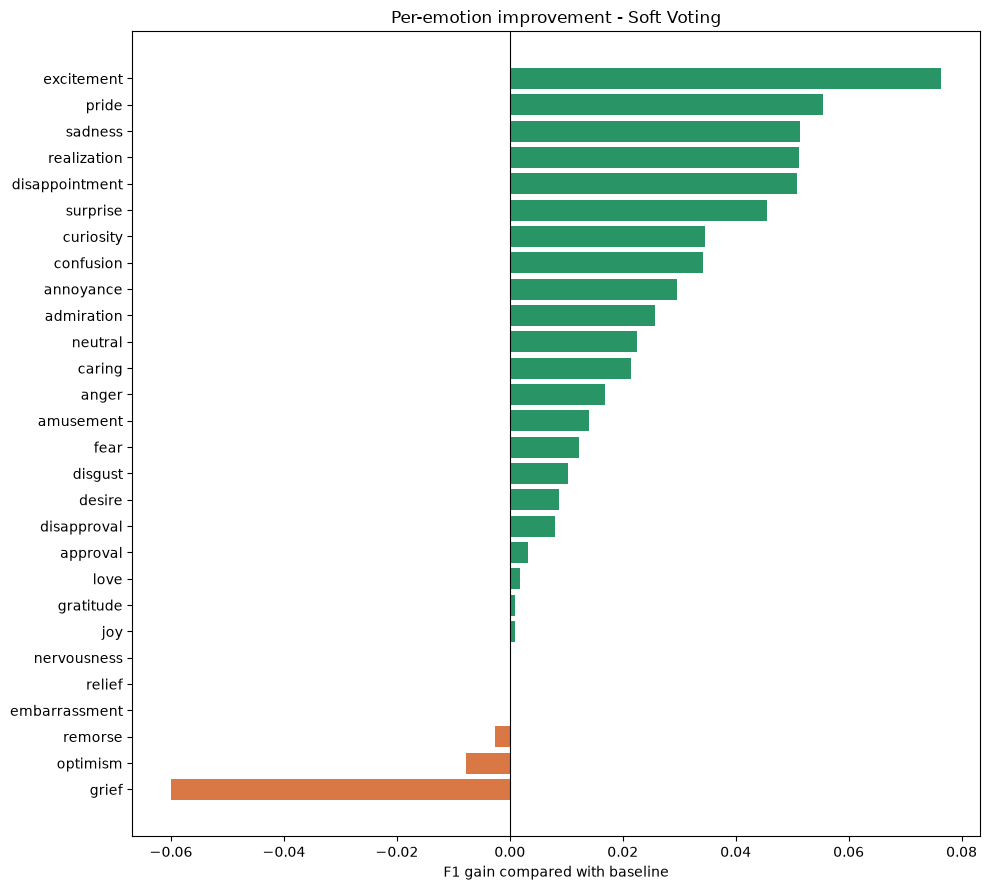

In [82]:
plot_df = gain_df.sort_values("f1_gain")

colors = [
    "#299567" if gain >= 0 else "#D97745"
    for gain in plot_df["f1_gain"]
]

plt.figure(figsize=(10, 9))

plt.barh(
    plot_df["emotion"],
    plot_df["f1_gain"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("F1 gain compared with baseline")
plt.title("Per-emotion improvement - Soft Voting")
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "soft_voting_gain.png"),
    dpi=150
)

plt.show()

gain_df.to_csv(
    os.path.join(OUT_DIR, "soft_voting_gain.csv"),
    index=False
)

### Interpretation of per-label improvements

Soft Voting improves F1 for 22 of the 28 labels,
while three remain unchanged and three deteriorate.

The largest improvements are observed for Excitement,
Pride, Sadness, Realization and Disappointment.

Several of these emotions were particularly difficult
for the baseline, suggesting that combining models
can reduce some of its weaknesses.

However, Grief shows a decrease in F1 from 0.56 to 0.50.

Since Grief has very low support, this difference must
be interpreted carefully.

The ensemble improves overall performance but does not
benefit every emotion equally.

## 7. Stacking methodology and leakage audit

The stacking implementation in 05_ensembles.ipynb
was reviewed to identify potential data leakage.

- TF-IDF vectorization is included inside each pipeline.
- Out-of-fold probabilities are generated on the
  training set using cross_val_predict.
- Multi-label stratified folds are used.
- The meta-model receives 112 features
  (28 probabilities from each of four base models).
- The meta-model is fitted on training data only.
- Validation thresholds are estimated by cross-fitting.
- Test probabilities are saved without computing
  final test scores.

One methodological limitation was identified:
Random Forest hyperparameters are selected on the
full training set before generating OOF predictions.

Nested cross-validation would provide stricter
independence between hyperparameter selection and
OOF prediction generation.

This does not constitute test-set leakage, but it
should be acknowledged as a methodological limitation.

No direct train-validation-test leakage was identified
during this static code review.

## 8. Conclusion and limitations

The error analysis highlights several limitations of
fine-grained multi-label emotion classification.

Neutral is frequently overpredicted by the baseline.
Related emotions such as Approval, Disapproval and
Annoyance are also difficult to distinguish.

The qualitative analysis identifies ambiguity,
multi-label difficulty and implicit emotions as
frequent potential sources of error.

Soft Voting improves F1 for 22 of the 28 labels and
reduces the number of misclassified comments by 197.

However, improvements are not uniform across emotions,
particularly for labels with very low support.

The qualitative categorization is AI-assisted,
subjective and based on a limited sample of 50 errors.
The original raw text is not available in the current
local Parquet export, so the analysis uses the available
processed text.

Future work will compare these error patterns with
DistilBERT to investigate whether contextual
representations address the limitations of linear
models and ensembles.